In [1]:
from pathlib import Path
import pandas as pd
import pyarrow.dataset as ds

In [16]:
DATA_DIR = Path("data")
df = pd.read_parquet("../data/films_merged.parquet")

Intercept : [6.5381978]
Coefficient : [-1.93708024e-10]
R² : 6.972206345667864e-05


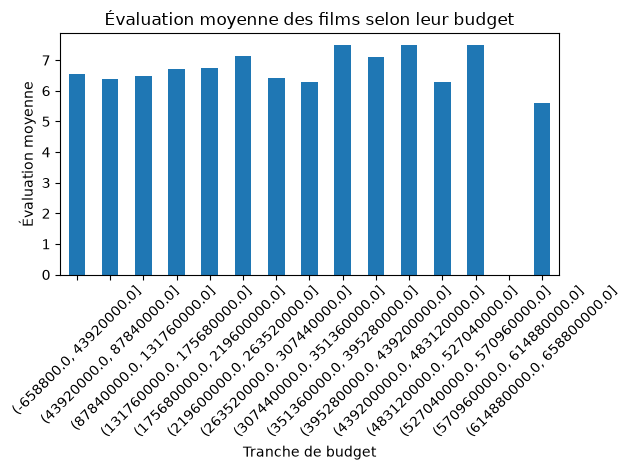

In [18]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


df_reg = df.dropna(subset = ["averageRating", "budget"])
y = df_reg[["averageRating"]]
X = df_reg[["budget"]]
modele = LinearRegression()
modele.fit(X, y)

print("Intercept :", modele.intercept_)
print("Coefficient :", modele.coef_[0])
print("R² :", modele.score(X, y))

df_reg["tranche_budget"] = pd.cut(
    df_reg["budget"],
    bins=15
)

df_reg["averageRating"] = pd.to_numeric(
    df_reg["averageRating"],
    errors="coerce"
)

moyennes = df_reg.groupby(
    "tranche_budget",
    observed=False
)["averageRating"].mean()

moyennes.plot(kind="bar")
plt.xlabel("Tranche de budget")
plt.ylabel("Évaluation moyenne")
plt.title("Évaluation moyenne des films selon leur budget")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()